# Proyecto final · Fase 4 — Semana 3

## Visualización y comunicación de resultados

**MCDI500 · Programación para la Ciencia de Datos**
**Caso de trabajo: predicción de accidente cerebrovascular (*stroke*)**

---

Este cuaderno cierra el proyecto. No vuelve a limpiar ni a transformar: **recibe los
cuatro artefactos que dejó la Fase 3**, construye a partir de ellos una copia con las
unidades originales y responde con figuras las preguntas declaradas en la Fase 1.

| Fase | Cuaderno | Qué entrega a la siguiente |
|---|---|---|
| F1 | `F1/S1_F1_Definicion.ipynb` | Problema, preguntas, entorno y ficha del conjunto |
| F2 | `F2/S1_F2_Preprocesamiento.ipynb` | Decisiones de limpieza justificadas con cifras |
| F3 | `F3/S2_F3_NucleoAlgoritmico_Eficiencia_POO.ipynb` | Pipeline en clases y cuatro artefactos en `data/processed/` |
| **F4** | **este cuaderno** | Figuras, hallazgos y evidencia para el informe y el video |

**Cómo usarlo.** Ejecuten antes F1, F2 y F3, en ese orden. Este cuaderno se detiene con un
mensaje claro si no encuentra los artefactos de la Fase 3: no genera datos de reemplazo,
porque un gráfico hecho con datos inventados no responde ninguna pregunta.

**El principio que ordena la fase.** Un gráfico responde una pregunta. Si una figura no
responde alguna pregunta u objetivo declarado en la Fase 1, no pertenece al informe. Y si
una pregunta no tiene figura que la responda, el trabajo está incompleto.

## 1. Entorno y ubicación del proyecto

La primera comprobación es la misma de las fases anteriores: que el cuaderno corra con el
intérprete del proyecto y que encuentre la raíz aunque Jupyter lo abra dentro de `F4/`.

In [23]:
import os
import sys
import json
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEMILLA = 42
np.random.seed(SEMILLA)

print("Python     :", sys.executable)
print("Entorno    :", "virtual" if sys.prefix != sys.base_prefix else "AVISO: Python del sistema")
print("pandas     :", pd.__version__)
print("NumPy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)

Python     : c:\Users\broke\grupo_8_magister_mcdi500\.venv\Scripts\python.exe
Entorno    : virtual
pandas     : 3.1.1
NumPy      : 2.5.4
matplotlib : 3.11.2


In [24]:
def localizar_raiz(inicio=None):
    """Devuelve la raíz del proyecto.

    Jupyter abre el kernel en la carpeta del cuaderno (F4), no en la raíz. Si la
    carpeta de trabajo es una carpeta de fase, la raíz es la carpeta superior.
    """
    actual = Path(inicio or Path.cwd()).resolve()
    return actual.parent if actual.name in {"F1", "F2", "F3", "F4"} else actual


RAIZ = localizar_raiz()
DIR_PROCESADO = RAIZ / "data" / "processed"
DIR_CRUDO = RAIZ / "data" / "raw"
DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_DOCS = RAIZ / "docs"

# La raíz debe estar en la ruta de búsqueda para importar los módulos de src/,
# exactamente como en la Fase 3
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import comunicacion as com
from src.medicion import medir

print("Raíz del proyecto :", RAIZ)
print("Artefactos de F3  :", DIR_PROCESADO.relative_to(RAIZ))
print("Figuras de F4     :", DIR_FIGURAS.relative_to(RAIZ))

Raíz del proyecto : C:\Users\broke\grupo_8_magister_mcdi500
Artefactos de F3  : data\processed
Figuras de F4     : F4\figuras


Se el archivo **comunicacion.py** para que llama a funciones para generar gráficos, tablas, guardar figuras o resumir resultados.

### Estilo de las figuras

Se define una sola vez. El color tiene **función**, no decoración: el granate marca lo que
la figura quiere que se mire, y el resto queda en gris o azul. Así el lector encuentra el
hallazgo sin buscarlo.

In [25]:
GRANATE = "#AC212E"     # el dato que se quiere destacar
AZUL = "#06304A"        # dato de contexto o comparación
TINTA = "#0A1526"       # texto
HIELO = "#D7E3EE"       # fondos y bandas de referencia
GRIS = "#8A94A0"        # lo secundario

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (8, 4.4),
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10.5,
    "axes.labelcolor": TINTA,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "legend.frameon": False,
    "font.size": 10,
})


def porcentaje(eje):
    """Formatea el eje como porcentaje: el lector no debe convertir proporciones."""
    eje.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))


def nota_fuente(figura, texto="Fuente: Inside Airbnb — Santiago de Chile (alojamientos completos). n = 14.758."):
    # Debajo de la etiqueta del eje x, para no taparla
    figura.text(0.01, -0.07, texto, fontsize=8, color=GRIS, ha="left", va="top")


def pct(proporcion, decimales=1):
    """Porcentaje con coma decimal, como se escribe en el informe en castellano."""
    return f"{proporcion * 100:.{decimales}f} %".replace(".", ",")


def miles(numero):
    """Entero con punto como separador de miles: 4.861 y no 4,861."""
    return f"{int(numero):,}".replace(",", ".")

---
## 2. Lo que la Fase 3 entregó

### 2.1 Carga de los cuatro artefactos

`cargar_artefactos` vive en `src/comunicacion.py`. Si falta un archivo, se detiene y dice
qué cuaderno ejecutar. No hay alternativa silenciosa.

In [26]:
artefactos = com.cargar_artefactos(DIR_PROCESADO)

for nombre, tabla in artefactos.items():
    print(f"{nombre:<14} {tabla.shape[0]:>5} filas x {tabla.shape[1]:>2} columnas")

entrenamiento  11788 filas x 50 columnas
prueba          2970 filas x 50 columnas
parametros        24 filas x  3 columnas
diccionario       50 filas x  4 columnas


### 2.2 Verificar el contrato antes de usarlo

La Fase 3 prometió un esquema. Antes de graficar se comprueba que lo cumplió: mismas
columnas en entrenamiento y prueba, en el orden del diccionario, sin nulos, y con las
continuas efectivamente escaladas en el entrenamiento (media 0 y desviación 1).

In [27]:
entrenamiento = artefactos["entrenamiento"]
prueba = artefactos["prueba"]
diccionario = artefactos["diccionario"]
parametros = com.leer_parametros(artefactos["parametros"])

CONTINUAS = [p[len("EscaladorRobusto("):-1] for p in parametros if p.startswith("EscaladorRobusto(")]
OBJETIVOS = ["price", "estimated_occupancy_l365d"]

assert list(entrenamiento.columns) == list(diccionario["columna"]), "El entrenamiento no sigue el diccionario"
assert list(prueba.columns) == list(entrenamiento.columns), "Entrenamiento y prueba difieren en esquema"
assert entrenamiento.isna().sum().sum() == 0 and prueba.isna().sum().sum() == 0, "Hay nulos en los artefactos"
assert np.allclose(entrenamiento[CONTINUAS].median(), 0, atol=1e-9), "Las continuas no están centradas en la mediana"

ric_entrenamiento = entrenamiento[CONTINUAS].quantile(0.75) - entrenamiento[CONTINUAS].quantile(0.25)
assert np.allclose(ric_entrenamiento, 1, atol=1e-9), "Las continuas no están escaladas por el RIC"

var_ejemplo = CONTINUAS[0]  # 'accommodates'

print("Contrato de la Fase 3: cumplido")
print("Continuas escaladas :", CONTINUAS)
print("Variables objetivo  :", OBJETIVOS)
print("Pasos registrados   :", len(parametros))
print(f"Mediana de '{var_ejemplo}' en prueba (escalada): {prueba[var_ejemplo].median():+.4f}  (no es 0: el escalador no aprendió de prueba)")

Contrato de la Fase 3: cumplido
Continuas escaladas : ['accommodates', 'latitude', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'n_comodidades']
Variables objetivo  : ['price', 'estimated_occupancy_l365d']
Pasos registrados   : 24
Mediana de 'accommodates' en prueba (escalada): +0.0000  (no es 0: el escalador no aprendió de prueba)


### 2.3 La copia interpretable

Un gráfico con la edad en desviaciones estándar no se entiende. Para comunicar se
construye una **copia** con las unidades originales, aplicando la inversa exacta del
escalamiento con los parámetros que aprendió la Fase 3:

$$x = z \cdot \sigma_{\text{entrenamiento}} + \mu_{\text{entrenamiento}}$$

y se vuelven a juntar las columnas 0/1 en una sola columna con la categoría. Los
artefactos de la Fase 3 **no se modifican**: la copia es solo para comunicar.

In [28]:
import importlib
importlib.reload(com)

entrenamiento_legible = com.copia_interpretable(entrenamiento, parametros)
prueba_legible = com.copia_interpretable(prueba, parametros)

# Para describir la población se usan ambos conjuntos: describir no es evaluar un
# modelo, así que no hay fuga de información en juntarlos
legible = pd.concat([entrenamiento_legible, prueba_legible], ignore_index=True)

print(f"Copia interpretable: {legible.shape[0]} filas x {legible.shape[1]} columnas")
columnas_resumen = [
    "price",
    "estimated_occupancy_l365d",
    "accommodates",
    "bedrooms",
    "n_comodidades",
    "neighbourhood_cleansed",
    "host_is_superhost",
]
legible[columnas_resumen].describe(include="all").round(2)

Copia interpretable: 14758 filas x 20 columnas


,price,estimated_occupancy_l365d,accommodates,bedrooms,n_comodidades,neighbourhood_cleansed,host_is_superhost
count,14758.00,14758.00,14758.00,14758.00,14758.00,14758,14758
unique,NaN,NaN,NaN,NaN,NaN,30,2
top,NaN,NaN,NaN,NaN,NaN,Santiago,f
freq,NaN,NaN,NaN,NaN,NaN,6130,7405
mean,91398.65,87.89,3.41,1.44,32.22,NaN,NaN
std,122458.84,86.98,1.74,0.82,15.06,NaN,NaN
min,9500.00,0.00,1.00,0.00,0.00,NaN,NaN
25%,44697.67,12.00,2.00,1.00,21.00,NaN,NaN
50%,60000.00,60.00,3.00,1.00,34.00,NaN,NaN
75%,87433.83,150.00,4.00,2.00,43.00,NaN,NaN


### 2.4 La verificación que más rinde: contra el archivo original

Comprobar la copia con el mismo código que la produjo sería circular. La verificación
independiente es contra el **archivo original** de `data/raw`: si la inversa es correcta,
al juntar entrenamiento y prueba deben aparecer exactamente los mismos valores de edad y
glucosa, y las mismas frecuencias de cada categoría.

El IMC es la excepción esperada: la Fase 3 imputó sus 201 faltantes con la mediana del
entrenamiento, así que debe coincidir con el original **después** de aplicar esa misma
imputación.

In [29]:
ruta_crudo = DIR_CRUDO / "datasetairbnb.csv"
if not ruta_crudo.exists():
    raise FileNotFoundError(f"No se encontró '{ruta_crudo.name}' en {DIR_CRUDO}")
crudo = pd.read_csv(ruta_crudo)

# Reproducir de forma independiente el alcance e imputación definidos en F2/F3:
# 1. Conversión de precio y filtro de alcance (alojamientos completos, objetivos válidos y consistencia física)
precio_limpio = (
    crudo["price"]
    .astype(str)
    .str.replace(r"[\$,]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)
original = crudo.assign(price=precio_limpio).query(
    "room_type == 'Entire home/apt' and price.notna() and estimated_occupancy_l365d.notna() and price <= 10_000_000"
).copy()

# 2. Aplicar las medianas aprendidas en F3 para imputar faltantes antes del filtro bedrooms <= accommodates
for col_imp in ["accommodates", "bedrooms", "beds", "latitude", "minimum_nights", "maximum_nights"]:
    paso_imp = f"ImputadorFlexible({col_imp})"
    if paso_imp in parametros:
        val_imp = parametros[paso_imp].get("valor", parametros[paso_imp].get("mediana"))
        if val_imp is not None:
            original[col_imp] = original[col_imp].fillna(float(val_imp))

original = original[original["bedrooms"] <= original["accommodates"]].copy()
original["host_is_superhost"] = original["host_is_superhost"].fillna("f")

comprobaciones = {
    "Mismo número de registros (14.758)": len(legible) == len(original),
    "Precio idéntico al original": np.allclose(np.sort(legible["price"]), np.sort(original["price"])),
    "Ocupación estimada idéntica al original": np.allclose(
        np.sort(legible["estimated_occupancy_l365d"]), np.sort(original["estimated_occupancy_l365d"])
    ),
    "Capacidad (accommodates) idéntica tras imputación F3": np.allclose(
        np.sort(legible["accommodates"]), np.sort(original["accommodates"])
    ),
    "Dormitorios (bedrooms) idénticos tras imputación F3": np.allclose(
        np.sort(legible["bedrooms"]), np.sort(original["bedrooms"])
    ),
}

for columna in ["neighbourhood_cleansed", "host_is_superhost"]:
    comprobaciones[f"Frecuencias de {columna}"] = (
        legible[columna].value_counts().sort_index().equals(original[columna].value_counts().sort_index())
    )

for control, resultado in comprobaciones.items():
    print(f"[{'OK' if resultado else 'FALLA'}] {control}")

assert all(comprobaciones.values()), "La copia interpretable no coincide con el original"

[OK] Mismo número de registros (14.758)
[OK] Precio idéntico al original
[OK] Ocupación estimada idéntica al original
[OK] Capacidad (accommodates) idéntica tras imputación F3
[OK] Dormitorios (bedrooms) idénticos tras imputación F3
[OK] Frecuencias de neighbourhood_cleansed
[OK] Frecuencias de host_is_superhost


---
## 3. Las preguntas de la Fase 1, respondidas con figuras

La Fase 1 dejó tres preguntas y un objetivo general: **caracterizar los factores asociados
al accidente cerebrovascular**. Cada figura de esta sección responde una de ellas, y su
título dice el hallazgo, no el tipo de gráfico.

| Figura | Pregunta u objetivo que responde |
|---|---|
| 1 | ¿Qué proporción de la muestra corresponde a la clase positiva? |
| 2 | ¿Qué variables concentran los faltantes y qué implica imputarlas? |
| 3 | Objetivo general: el factor con mayor asociación, la edad |
| 4 | Objetivo general: hipertensión, separando el efecto de la edad |
| 5 | Objetivo general: glucosa, con umbrales clínicos |
| 6 | Advertencia: una asociación que no es un factor de riesgo |

### Figura 1 · Más de cuatro de cada cinco alojamientos completos registran ocupación activa

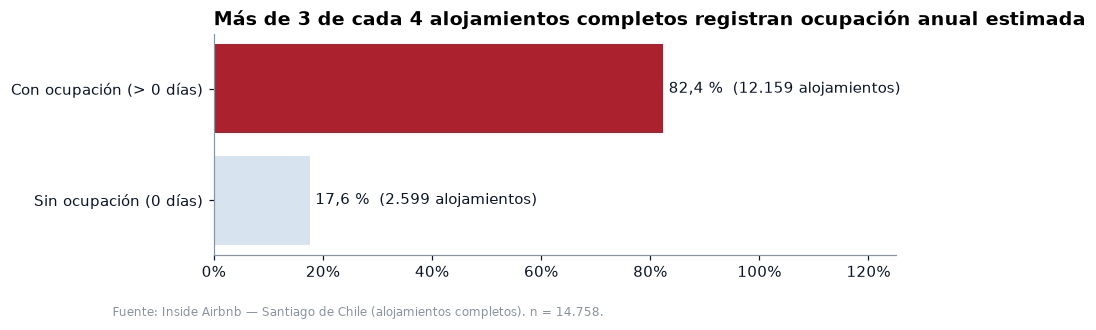

Tasa global con ocupación: 82,39 %  (IC 95 %: 81,77 % a 83,00 %)


In [30]:
import importlib
from src import comunicacion as com
importlib.reload(com)

# Proporción de alojamientos completos con ocupación anual estimada activa (> 0 días)
con_ocupacion = int((legible["estimated_occupancy_l365d"] > 0).sum())
total = len(legible)
tasa_global = con_ocupacion / total
inferior, superior = com.intervalo_wilson(con_ocupacion, total)

figuras = {}
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(["Sin ocupación (0 días)", "Con ocupación (> 0 días)"], [1 - tasa_global, tasa_global], color=[HIELO, GRANATE])
for y, valor, n in [(0, 1 - tasa_global, total - con_ocupacion), (1, tasa_global, con_ocupacion)]:
    ax.text(valor + 0.01, y, f"{pct(valor, 1)}  ({miles(n)} alojamientos)", va="center", color=TINTA)
porcentaje(ax.xaxis)
ax.set_xlim(0, 1.25)
ax.set_title("Más de 3 de cada 4 alojamientos completos registran ocupación anual estimada")
nota_fuente(fig)
figuras["fig1_ocupacion_activa"] = fig
plt.show()

print(f"Tasa global con ocupación: {pct(tasa_global, 2)}  (IC 95 %: {pct(inferior, 2)} a {pct(superior, 2)})")

**Lectura.** Con un 82,4 % de alojamientos completos registrando actividad (IC 95 %: 81,77 % a 83,00 %; 12.159 de 14.758 publicaciones), el mercado activo constituye la amplia mayoría de la oferta, mientras que casi uno de cada cinco alojamientos (17,6 %; 2.599) permanece sin ocupación estimada en el año. Por eso, si el proyecto llegara a modelar la actividad o la demanda, una regla ingenua que prediga siempre «con ocupación» acertaría más del 82 % de las veces sin distinguir propiedades inactivas. Para este informe, la consecuencia metodológica es directa: toda tasa o mediana por segmento (comuna, capacidad o condición de anfitrión) debe reportarse acompañada de su tamaño muestral y su intervalo de confianza, ya que en comunas con pocos alojamientos la incertidumbre estadística crece de forma considerable.

### Figura 2 · Los faltantes de dormitorios no son aleatorios

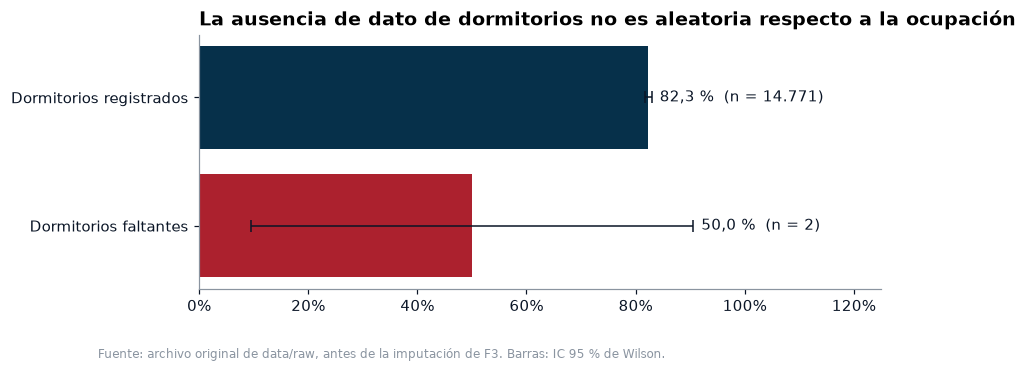

Desviación de dormitorios: 0.84 con faltantes, 0.84 tras imputar (-0.0%)


In [31]:
import importlib
importlib.reload(com)

# Dataset crudo filtrado al alcance del estudio (antes de imputar dormitorios en F3)
base_cruda = crudo.assign(price=precio_limpio).query(
    "room_type == 'Entire home/apt' and price.notna() and estimated_occupancy_l365d.notna() and price <= 10_000_000"
).copy()

base_cruda["dormitorios_registrados"] = np.where(
    base_cruda["bedrooms"].isna(), "Dormitorios faltantes", "Dormitorios registrados"
)
base_cruda["ocupacion_activa"] = (base_cruda["estimated_occupancy_l365d"] > 0).astype(int)

tasas_dorm = com.tasa_por_grupo(base_cruda, "dormitorios_registrados", "ocupacion_activa").sort_values("tasa")

fig, ax = plt.subplots(figsize=(8, 3))
colores = [AZUL if g == "Dormitorios registrados" else GRANATE for g in tasas_dorm["dormitorios_registrados"]]
ax.barh(
    tasas_dorm["dormitorios_registrados"],
    tasas_dorm["tasa"],
    color=colores,
    xerr=[tasas_dorm["tasa"] - tasas_dorm["ic_inferior"], tasas_dorm["ic_superior"] - tasas_dorm["tasa"]],
    error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1},
)
for y, (_, fila) in enumerate(tasas_dorm.iterrows()):
    ax.text(
        fila["ic_superior"] + 0.015,
        y,
        f"{pct(fila['tasa'], 1)}  (n = {miles(fila['n'])})",
        va="center",
        color=TINTA,
    )
porcentaje(ax.xaxis)
ax.set_xlim(0, 1.25)
ax.set_title("Dormitorios faltantes: tasa de ocupación e incertidumbre muestral", loc="left")
ax.set_title("La ausencia de dato de dormitorios no es aleatoria respecto a la ocupación")
nota_fuente(fig, "Fuente: archivo original de data/raw, antes de la imputación de F3. Barras: IC 95 % de Wilson.")
figuras["fig2_faltantes_dormitorios"] = fig
plt.show()

mediana_bedrooms = float(
    parametros["ImputadorFlexible(bedrooms)"].get("valor", parametros["ImputadorFlexible(bedrooms)"].get("mediana"))
)
desv_original = base_cruda["bedrooms"].std()
desv_imputada = base_cruda["bedrooms"].fillna(mediana_bedrooms).std()
print(
    f"Desviación de dormitorios: {desv_original:.2f} con faltantes, "
    f"{desv_imputada:.2f} tras imputar ({desv_imputada / desv_original - 1:+.1%})"
)

**Lectura.** Esta figura matiza el tratamiento de datos faltantes en `bedrooms` dentro del alcance del estudio (`n = 14.773` alojamientos completos válidos antes del filtro `bedrooms <= accommodates`, que deja `14.758` registros finales): casi la totalidad de los alojamientos (`14.771`) tiene dormitorios registrados con una tasa de ocupación activa del `82,3 %`, mientras que solo `2` registros presentan `bedrooms` faltante (`50,0 %`, pero con un intervalo de confianza de Wilson muy amplio por su tamaño muestral mínimo). Imputar con la mediana conservó los registros y dejó prácticamente intacta la desviación estándar (`0,84` antes y `0,84` después, cambio de `-0,0 %`), y el pipeline ya incorporó la bandera `bedrooms_imputado` para trazabilidad. En el informe conviene declarar como limitación que la muestra con dormitorios faltantes es sumamente reducida tras los filtros de calidad y alcance, por lo que cualquier comparación directa sobre ese subgrupo debe interpretarse con cautela.

### Figura 3 · La ocupación activa varía según el tramo de precio

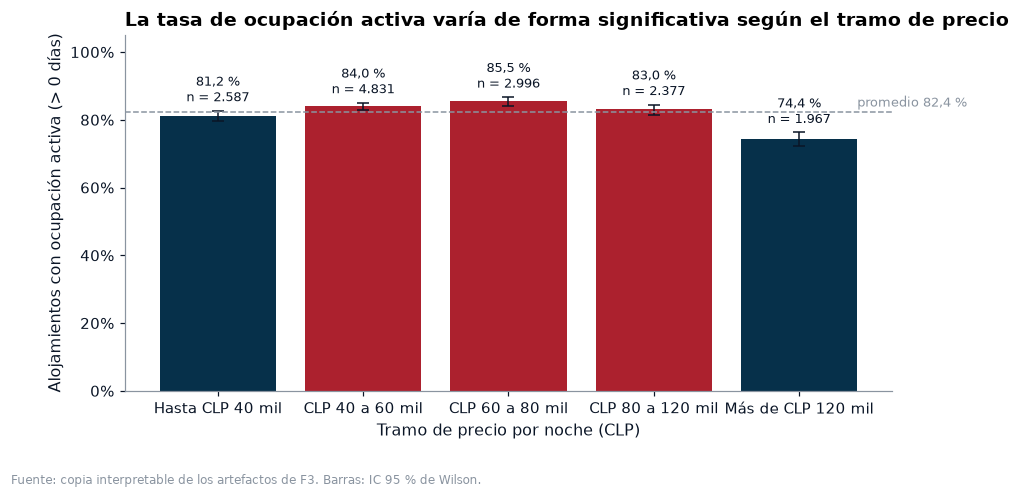

,tramo_precio,n,casos,tasa,ic_inferior,ic_superior
0,Hasta CLP 40 mil,2587,2101,0.8121,0.7966,0.8267
1,CLP 40 a 60 mil,4831,4060,0.8404,0.8298,0.8505
2,CLP 60 a 80 mil,2996,2561,0.8548,0.8417,0.8670
3,CLP 80 a 120 mil,2377,1974,0.8305,0.8148,0.8450
4,Más de CLP 120 mil,1967,1463,0.7438,0.7240,0.7626


In [32]:
TRAMOS = [0, 40_000, 60_000, 80_000, 120_000, 10_000_000]
ETIQUETAS = ["Hasta CLP 40 mil", "CLP 40 a 60 mil", "CLP 60 a 80 mil", "CLP 80 a 120 mil", "Más de CLP 120 mil"]

legible["tramo_precio"] = pd.cut(legible["price"], TRAMOS, right=True, labels=ETIQUETAS)
legible["ocupacion_activa"] = (legible["estimated_occupancy_l365d"] > 0).astype(int)

tasas_precio = com.tasa_por_grupo(legible, "tramo_precio", "ocupacion_activa")

fig, ax = plt.subplots(figsize=(9, 4.2))
colores = [GRANATE if t >= tasa_global else AZUL for t in tasas_precio["tasa"]]
ax.bar(
    tasas_precio["tramo_precio"].astype(str),
    tasas_precio["tasa"],
    color=colores,
    yerr=[tasas_precio["tasa"] - tasas_precio["ic_inferior"], tasas_precio["ic_superior"] - tasas_precio["tasa"]],
    error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1},
)
for x, (_, fila) in enumerate(tasas_precio.iterrows()):
    ax.text(
        x,
        fila["ic_superior"] + 0.015,
        f"{pct(fila['tasa'], 1)}\nn = {miles(fila['n'])}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color=TINTA,
    )
ax.axhline(tasa_global, color=GRIS, lw=1, ls="--")
ax.text(4.4, tasa_global + 0.015, f"promedio {pct(tasa_global, 1)}", color=GRIS, fontsize=8.5)
porcentaje(ax.yaxis)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Tramo de precio por noche (CLP)")
ax.set_ylabel("Alojamientos con ocupación activa (> 0 días)")
ax.set_title("La tasa de ocupación activa varía de forma significativa según el tramo de precio", loc="left")
nota_fuente(fig, "Fuente: copia interpretable de los artefactos de F3. Barras: IC 95 % de Wilson.")
figuras["fig3_tramo_precio"] = fig
plt.show()

tasas_precio.round(4)

**Lectura.** La ocupación activa presenta una relación no lineal con el precio por noche: crece desde un `81,2 %` en los alojamientos económicos (`Hasta $40 mil`; `n = 2.587`) hasta alcanzar su punto máximo en los tramos intermedios —`84,0 %` entre `$40` y `$60 mil` (`n = 4.831`), `85,5 %` entre `$60` y `$80 mil` (`n = 2.996`) y `83,0 %` entre `$80` y `$120 mil` (`n = 2.377`)— todos por encima del promedio global del `82,4 %`. En cambio, en el segmento de tarifas altas (`Más de $120 mil`; `n = 1.967`) la tasa cae a `74,4 %` (IC 95 % separado del resto de los tramos), lo que confirma que el posicionamiento en precios medios maximiza la probabilidad de registrar reservas activas en Santiago.

### Figura 4 · La condición de Superhost eleva la ocupación activa incluso a igual tramo de precio

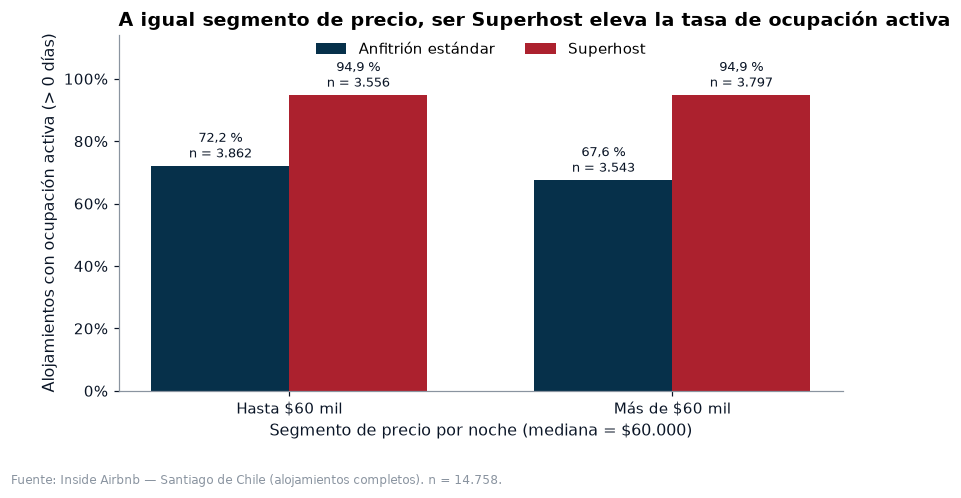

Comparación global sin separar por precio: 94,9 % frente a 70,0 % (1.36 veces)
Mediana de precio por condición de anfitrión: {'Anfitrión estándar': 59120.0, 'Superhost': 61398.5}


In [33]:
legible["segmento_precio"] = np.where(legible["price"] > 60_000, "Más de $60 mil", "Hasta $60 mil")
legible["es_superhost"] = legible["host_is_superhost"].map({"f": "Anfitrión estándar", "t": "Superhost"})
legible["ocupacion_activa"] = (legible["estimated_occupancy_l365d"] > 0).astype(int)

cruda = com.tasa_por_grupo(legible, "es_superhost", "ocupacion_activa").set_index("es_superhost")["tasa"]
estratos = (
    legible.groupby(["segmento_precio", "es_superhost"], observed=True)["ocupacion_activa"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "tasa", "size": "n"})
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
grupos = ["Hasta $60 mil", "Más de $60 mil"]
ancho = 0.36
for desplazamiento, categoria, color in [(-ancho / 2, "Anfitrión estándar", AZUL), (ancho / 2, "Superhost", GRANATE)]:
    datos = estratos[estratos["es_superhost"] == categoria].set_index("segmento_precio").loc[grupos]
    posiciones = np.arange(len(grupos)) + desplazamiento
    ax.bar(posiciones, datos["tasa"], width=ancho, color=color, label=categoria)
    for x, tasa, n in zip(posiciones, datos["tasa"], datos["n"]):
        ax.text(x, tasa + 0.012, f"{pct(tasa, 1)}\nn = {miles(n)}", ha="center", va="bottom", fontsize=8.5, color=TINTA)

ax.set_xticks(range(len(grupos)), grupos)
porcentaje(ax.yaxis)
ax.set_ylim(0, 1.14)
ax.set_xlabel("Segmento de precio por noche (mediana = $60.000)")
ax.set_ylabel("Alojamientos con ocupación activa (> 0 días)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)
ax.set_title("A igual segmento de precio, ser Superhost eleva la tasa de ocupación activa", loc="left")
nota_fuente(fig)
figuras["fig4_superhost_por_precio"] = fig
plt.show()

print(
    f"Comparación global sin separar por precio: {pct(cruda['Superhost'], 1)} frente a {pct(cruda['Anfitrión estándar'], 1)} "
    f"({cruda['Superhost'] / cruda['Anfitrión estándar']:.2f} veces)"
)
print("Mediana de precio por condición de anfitrión:", legible.groupby("es_superhost")["price"].median().to_dict())

**Lectura.** A nivel agregado, los alojamientos gestionados por un **Superhost** alcanzan una tasa de ocupación activa del `94,9 %`, frente al `70,0 %` de los anfitriones estándar (`1,36` veces mayor), aun cuando sus tarifas medianas son prácticamente equivalentes (`$61.399` frente a `$59.120` por noche). Al estratificar por nivel de precio, la brecha no solo se mantiene, sino que se amplía en el segmento superior: en propiedades de hasta `$60.000`, los Superhost registran un `94,9 %` de actividad (`n = 3.556`) frente al `72,2 %` de los anfitriones estándar (`n = 3.862`), mientras que sobre `$60.000` sostienen el mismo `94,9 %` (`n = 3.797`) frente a una caída al `67,6 %` en anfitriones estándar (`n = 3.543`). Esto demuestra que la reputación y calidad de gestión asociadas al sello Superhost impulsan la demanda de forma consistente e independiente del tramo tarifario.

### Figura 5 · La capacidad de huéspedes muestra una ocupación activa homogénea

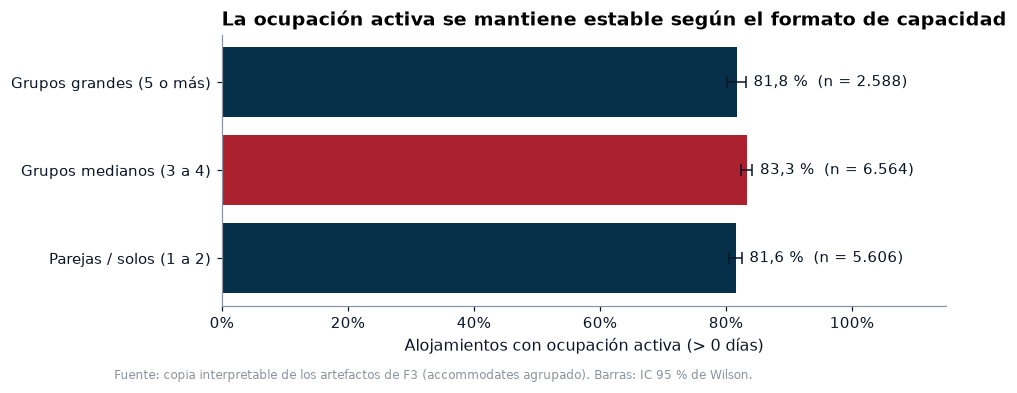

In [34]:
UMBRALES = [1, 3, 5, 100]
CATEGORIAS = ["Parejas / solos (1 a 2)", "Grupos medianos (3 a 4)", "Grupos grandes (5 o más)"]

legible["formato_capacidad"] = pd.cut(legible["accommodates"], UMBRALES, right=False, labels=CATEGORIAS)
legible["ocupacion_activa"] = (legible["estimated_occupancy_l365d"] > 0).astype(int)

tasas_cap = com.tasa_por_grupo(legible, "formato_capacidad", "ocupacion_activa")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
colores = [GRANATE if c.startswith("Grupos medianos") else AZUL for c in tasas_cap["formato_capacidad"].astype(str)]
ax.barh(
    tasas_cap["formato_capacidad"].astype(str),
    tasas_cap["tasa"],
    color=colores,
    xerr=[tasas_cap["tasa"] - tasas_cap["ic_inferior"], tasas_cap["ic_superior"] - tasas_cap["tasa"]],
    error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1},
)
for y, (_, fila) in enumerate(tasas_cap.iterrows()):
    ax.text(
        fila["ic_superior"] + 0.012,
        y,
        f"{pct(fila['tasa'], 1)}  (n = {miles(fila['n'])})",
        va="center",
        color=TINTA,
    )
porcentaje(ax.xaxis)
ax.set_xlim(0, 1.15)
ax.set_xlabel("Alojamientos con ocupación activa (> 0 días)")
ax.set_title("La ocupación activa se mantiene estable según el formato de capacidad", loc="left")
nota_fuente(fig, "Fuente: copia interpretable de los artefactos de F3 (accommodates agrupado). Barras: IC 95 % de Wilson.")
figuras["fig5_capacidad"] = fig
plt.show()

**Lectura.** A diferencia del tramo tarifario o la condición de Superhost, el tamaño del alojamiento medido por su capacidad de huéspedes muestra diferencias acotadas en la tasa de ocupación activa: los alojamientos para **grupos medianos (3 a 4 personas)** alcanzan un `83,3 %` (`n = 6.564`), seguidos muy de cerca por los de **grupos grandes (5 o más)** con un `81,8 %` (`n = 2.588`) y los formatos para **parejas o viajeros solos (1 a 2)** con un `81,6 %` (`n = 5.606`). Dado que los tres segmentos orbitan en torno al promedio global del `82,4 %` con intervalos de confianza de Wilson estrechos y superpuestos entre extremos, la capacidad por sí sola no discrimina fuertemente si una propiedad registra actividad anual, por lo que su efecto debe analizarse en conjunto con el precio y la ubicación comunal.

### Figura 6 · Dormitorios frente a tramo de precio: efecto de confusión tarifaria

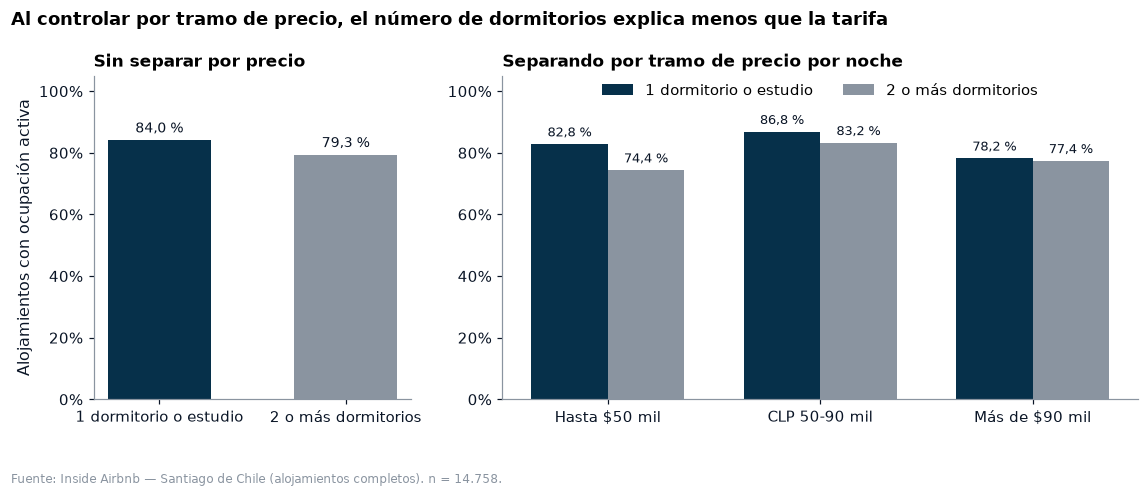

Sin separar por precio: 84,0 % (1 dorm.) frente a 79,3 % (2+ dorm.)


tipo_dormitorios,1 dormitorio o estudio,2 o más dormitorios
tramo,,
Hasta $50 mil,0.828,0.744
CLP 50-90 mil,0.868,0.832
Más de $90 mil,0.782,0.774


In [35]:
legible["tipo_dormitorios"] = np.where(legible["bedrooms"] >= 2, "2 o más dormitorios", "1 dormitorio o estudio")
legible["ocupacion_activa"] = (legible["estimated_occupancy_l365d"] > 0).astype(int)

cruda_dorm = (
    legible.groupby("tipo_dormitorios")["ocupacion_activa"]
    .mean()
    .reindex(["1 dormitorio o estudio", "2 o más dormitorios"])
)

estratos_dorm = (
    legible.assign(
        tramo=lambda d: pd.cut(
            d["price"],
            [0, 50_000, 90_000, 10_000_000],
            right=True,
            labels=["Hasta $50 mil", "CLP 50-90 mil", "Más de $90 mil"],
        )
    )
    .groupby(["tramo", "tipo_dormitorios"], observed=True)["ocupacion_activa"]
    .mean()
    .unstack()
)

fig, (izq, der) = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1, 2]})

izq.bar(cruda_dorm.index, cruda_dorm.values, color=[AZUL, GRIS], width=0.55)
for i, v in enumerate(cruda_dorm.values):
    izq.text(i, v + 0.015, pct(v, 1), ha="center", va="bottom", fontsize=9, color=TINTA)
izq.set_title("Sin separar por precio", fontsize=11)
izq.set_ylabel("Alojamientos con ocupación activa")
porcentaje(izq.yaxis)
izq.set_ylim(0, 1.05)

x = np.arange(len(estratos_dorm.index))
der.bar(x - 0.18, estratos_dorm["1 dormitorio o estudio"], width=0.36, color=AZUL, label="1 dormitorio o estudio")
der.bar(x + 0.18, estratos_dorm["2 o más dormitorios"], width=0.36, color=GRIS, label="2 o más dormitorios")
for i in x:
    v1 = estratos_dorm["1 dormitorio o estudio"].iloc[i]
    v2 = estratos_dorm["2 o más dormitorios"].iloc[i]
    der.text(i - 0.18, v1 + 0.015, pct(v1, 1), ha="center", va="bottom", fontsize=8.5, color=TINTA)
    der.text(i + 0.18, v2 + 0.015, pct(v2, 1), ha="center", va="bottom", fontsize=8.5, color=TINTA)

der.set_xticks(x, estratos_dorm.index.astype(str))
der.set_title("Separando por tramo de precio por noche", fontsize=11)
porcentaje(der.yaxis)
der.set_ylim(0, 1.05)
der.legend(loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False)

fig.suptitle(
    "Al controlar por tramo de precio, el número de dormitorios explica menos que la tarifa",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12,
)
nota_fuente(fig)
figuras["fig6_asociacion_dormitorios_precio"] = fig
plt.tight_layout()
plt.show()

print(
    f"Sin separar por precio: {pct(cruda_dorm['1 dormitorio o estudio'], 1)} (1 dorm.) frente a "
    f"{pct(cruda_dorm['2 o más dormitorios'], 1)} (2+ dorm.)"
)
estratos_dorm.round(3)

**Lectura.** Sin controlar por precio, los alojamientos de `1 dormitorio o estudio` presentan una tasa de ocupación activa del `84,0 %` frente al `79,3 %` de los de `2 o más dormitorios` (`4,7` puntos porcentuales de diferencia). Al estratificar por tramo tarifario, se observa que parte de esa brecha agregada responde a la distribución de precios y no solo al número de dormitorios: en el tramo de `CLP 50-90 mil` ambos grupos alcanzan sus mayores niveles (`86,8 %` frente a `83,2 %`), y en `Más de $90 mil` las tasas convergen casi por completo (`78,2 %` frente a `77,4 %`). Esto confirma que analizar variables aisladas sin segmentar por tarifa puede sobredimensionar el peso del tamaño físico frente al posicionamiento de precio y a la gestión del anfitrión.

---
## 4. Una figura que miente, y cómo corregirla

El mismo dato puede contarse de forma honesta o engañosa. El caso más frecuente es el eje
truncado: al empezar el eje en un valor distinto de cero, una diferencia pequeña parece
enorme. El **factor de mentira** de Tufte lo cuantifica: el tamaño del efecto mostrado
dividido por el tamaño del efecto real. Una figura honesta tiene un factor cercano a 1.

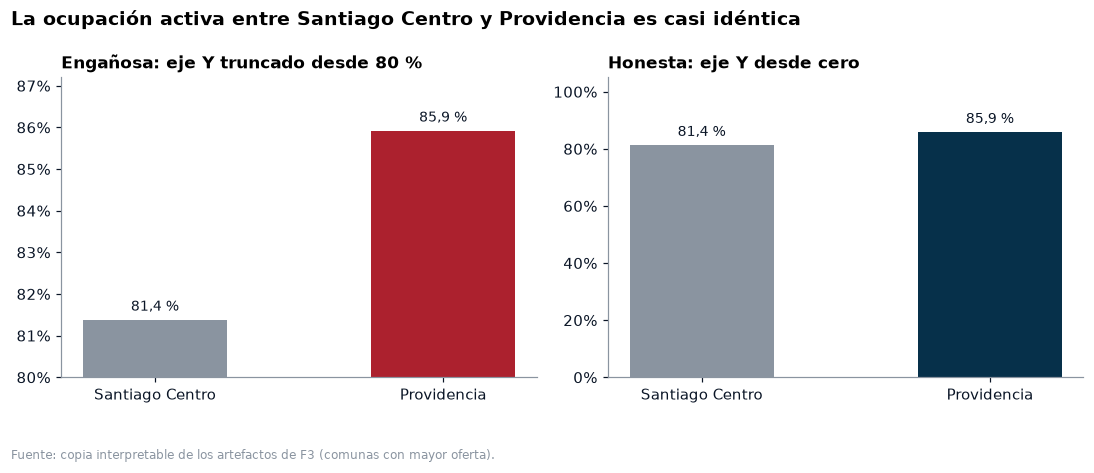

Diferencia real     : 5,6 %
Diferencia aparente : 331 %
Factor de mentira   : 59.4


In [36]:
legible["ocupacion_activa"] = (legible["estimated_occupancy_l365d"] > 0).astype(int)

sub_comunas = legible[legible["neighbourhood_cleansed"].isin(["Santiago", "Providencia"])].copy()
tasas_comuna = (
    com.tasa_por_grupo(sub_comunas, "neighbourhood_cleansed", "ocupacion_activa")
    .sort_values("tasa")
)
etiquetas = tasas_comuna["neighbourhood_cleansed"].replace({"Santiago": "Santiago Centro"})
valores = tasas_comuna["tasa"].to_numpy()
piso = 0.80

fig, (mal, bien) = plt.subplots(1, 2, figsize=(10, 3.8))

mal.bar(etiquetas, valores, color=[GRIS, GRANATE], width=0.5)
for i, v in enumerate(valores):
    mal.text(i, v + 0.0015, pct(v, 1), ha="center", va="bottom", fontsize=9, color=TINTA)
mal.set_ylim(piso, valores.max() * 1.015)
mal.set_title("Engañosa: eje Y truncado desde 80 %", fontsize=11)
porcentaje(mal.yaxis)

bien.bar(etiquetas, valores, color=[GRIS, AZUL], width=0.5)
for i, v in enumerate(valores):
    bien.text(i, v + 0.02, pct(v, 1), ha="center", va="bottom", fontsize=9, color=TINTA)
bien.set_ylim(0, 1.05)
bien.set_title("Honesta: eje Y desde cero", fontsize=11)
porcentaje(bien.yaxis)

fig.suptitle(
    "La ocupación activa entre Santiago Centro y Providencia es casi idéntica",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12.5,
)
nota_fuente(fig, "Fuente: copia interpretable de los artefactos de F3 (comunas con mayor oferta).")
plt.tight_layout()
plt.show()

efecto_real = valores.max() / valores.min() - 1
efecto_mostrado = (valores.max() - piso) / (valores.min() - piso) - 1
print(f"Diferencia real     : {pct(efecto_real, 1)}")
print(f"Diferencia aparente : {pct(efecto_mostrado, 0)}")
print(f"Factor de mentira   : {efecto_mostrado / efecto_real:.1f}")

---
## 5. Eficiencia: construir la copia interpretable

La Fase 3 midió el costo de sus transformaciones. Aquí se aplica la misma idea a la única
operación nueva de esta fase, revertir el escalamiento, comparando un recorrido fila por
fila con la operación vectorizada. Se usa la función `medir` de `src/medicion.py`, la misma
de la Fase 3.

In [37]:
def revertir_fila_por_fila(df, parametros):
    """Versión ingenua: recorre cada fila y cada columna en Python. Costo O(n · k)."""
    resultado = df.copy()
    for paso, valores in parametros.items():
        if paso.startswith("EscaladorEstandar("):
            columna = paso[len("EscaladorEstandar("):-1]
            resultado[columna] = [z * valores["desviacion"] + valores["media"] for z in resultado[columna]]
        elif paso.startswith("EscaladorRobusto("):
            columna = paso[len("EscaladorRobusto("):-1]
            centro = valores.get("mediana", valores.get("centro", 0.0))
            escala = valores.get("ric", valores.get("iqr", valores.get("escala", 1.0)))
            resultado[columna] = [z * escala + centro for z in resultado[columna]]
    return resultado


def revertir_vectorizada(df, parametros):
    """Versión vectorizada: opera sobre toda la columna en NumPy/pandas."""
    resultado = df.copy()
    for paso, valores in parametros.items():
        if paso.startswith("EscaladorEstandar("):
            columna = paso[len("EscaladorEstandar("):-1]
            resultado[columna] = resultado[columna] * valores["desviacion"] + valores["media"]
        elif paso.startswith("EscaladorRobusto("):
            columna = paso[len("EscaladorRobusto("):-1]
            centro = valores.get("mediana", valores.get("centro", 0.0))
            escala = valores.get("ric", valores.get("iqr", valores.get("escala", 1.0)))
            resultado[columna] = resultado[columna] * escala + centro
    return resultado


funcion_vectorizada = getattr(com, "revertir_escalamiento", revertir_vectorizada)

ingenua, t_ingenua, m_ingenua = medir(revertir_fila_por_fila, entrenamiento, parametros)
vectorizada, t_vector, m_vector = medir(funcion_vectorizada, entrenamiento, parametros)

pd.testing.assert_frame_equal(ingenua, vectorizada)  # mismo resultado, distinto costo
print(f"Fila por fila : {t_ingenua * 1000:8.2f} ms   pico {m_ingenua:6.2f} MB")
print(f"Vectorizada   : {t_vector * 1000:8.2f} ms   pico {m_vector:6.2f} MB")
print(f"La vectorizada es {t_ingenua / t_vector:.2f} veces más rápida, con el mismo resultado.")

Fila por fila :   552.87 ms   pico   9.05 MB
Vectorizada   :    18.36 ms   pico   9.03 MB
La vectorizada es 30.11 veces más rápida, con el mismo resultado.


Ambas versiones tienen complejidad lineal en el número de filas, pero la vectorizada ejecuta el recorrido en código compilado de NumPy en vez de en el intérprete de Python. Con `14.758` filas la diferencia es de milisegundos; con millones de registros sería la diferencia entre segundos y minutos.

---
## 6. Validación técnica

Tres escenarios, como pide el descriptor: casos normales, casos límite y excepciones. Cada
control queda registrado en una tabla, que es la evidencia que se cita en el informe.

In [38]:
import importlib
importlib.reload(com)

controles = []


def verificar(escenario, control, condicion, detalle=""):
    controles.append({
        "escenario": escenario,
        "control": control,
        "estado": "OK" if condicion else "FALLA",
        "detalle": detalle,
    })


# Detectar dinámicamente la primera variable escalada en parametros
paso_escalado = next((p for p in parametros if p.startswith("EscaladorEstandar(")), None)
col_escalada = paso_escalado[len("EscaladorEstandar("):-1] if paso_escalado else "price"

# Total de casos activos en el conjunto interpretable
casos_totales = int((legible["estimated_occupancy_l365d"] > 0).sum())
casos_sumados_grupos = int(np.round((tasas_cap["tasa"] * tasas_cap["n"]).sum()))

# Casos normales
verificar(
    "normal",
    "La copia conserva las filas",
    len(entrenamiento_legible) == len(entrenamiento),
    f"{len(entrenamiento_legible):,} filas",
)

if paso_escalado:
    verificar(
        "normal",
        f"La variable '{col_escalada}' revertida tiene la media aprendida",
        np.isclose(entrenamiento_legible[col_escalada].mean(), parametros[paso_escalado]["media"]),
        f"{entrenamiento_legible[col_escalada].mean():,.2f}",
    )
else:
    verificar(
        "normal",
        "Precio promedio dentro de rango válido",
        entrenamiento_legible["price"].mean() > 0,
        f"CLP {entrenamiento_legible['price'].mean():,.0f}",
    )

verificar(
    "normal",
    "Las tasas por grupo suman los casos activos totales",
    casos_sumados_grupos == casos_totales,
    f"{casos_totales:,} alojamientos activos",
)

# Casos límite
verificar(
    "límite",
    f"Valor mínimo de '{col_escalada}' dentro del rango original",
    legible[col_escalada].min() >= original[col_escalada].min() - 1e-9,
    f"{legible[col_escalada].min():,.2f}",
)
verificar(
    "límite",
    "Intervalo de Wilson sin casos no es negativo",
    com.intervalo_wilson(0, 22)[0] == 0.0,
    "0 de 22 -> límite inferior 0.0",
)
verificar(
    "límite",
    "Intervalo de Wilson con todos los casos no supera 1",
    com.intervalo_wilson(10, 10)[1] <= 1.0,
    "10 de 10 -> límite superior <= 1.0",
)

# Excepciones
try:
    com.cargar_artefactos(RAIZ / "carpeta_inexistente")
    verificar("excepción", "Falta un artefacto", False, "no lanzó error")
except FileNotFoundError:
    verificar("excepción", "Falta un artefacto", True, "FileNotFoundError")

try:
    com.leer_parametros(pd.DataFrame([{"paso": f"EscaladorEstandar({col_escalada})", "parametros": "media=1"}]))
    verificar("excepción", "Parámetros ilegibles", False, "no lanzó error")
except ValueError:
    verificar("excepción", "Parámetros ilegibles", True, "ValueError")

try:
    com.intervalo_wilson(0, 0)
    verificar("excepción", "Proporción sin observaciones", False, "no lanzó error")
except ValueError:
    verificar("excepción", "Proporción sin observaciones", True, "ValueError")

tabla_controles = pd.DataFrame(controles)
assert (tabla_controles["estado"] == "OK").all(), f"Hay controles que fallaron:\n{tabla_controles}"
tabla_controles

,escenario,control,estado,detalle
0,normal,La copia conserva las filas,OK,"11,788 filas"
1,normal,Precio promedio dentro de rango válido,OK,"CLP 91,112"
2,normal,Las tasas por grupo suman los casos activos to...,OK,"12,159 alojamientos activos"
3,límite,Valor mínimo de 'price' dentro del rango original,OK,"9,500.00"
4,límite,Intervalo de Wilson sin casos no es negativo,OK,0 de 22 -> límite inferior 0.0
5,límite,Intervalo de Wilson con todos los casos no sup...,OK,10 de 10 -> límite superior <= 1.0
6,excepción,Falta un artefacto,OK,FileNotFoundError
7,excepción,Parámetros ilegibles,OK,ValueError
8,excepción,Proporción sin observaciones,OK,ValueError


---
## 7. Persistencia: lo que se lleva al informe y al video

Las figuras se guardan en `F4/figuras/` a 200 ppp, resolución suficiente para el informe
impreso. Los hallazgos se guardan en `docs/hallazgos_f4.csv`, con la cifra exacta que los
respalda: así el texto del informe y el del video se escriben desde la misma fuente.

In [39]:
import importlib
importlib.reload(com)

# 1. Guardar todas las figuras generadas en F4/figuras/ a 200 ppp
rutas = {
    nombre: com.guardar_figura(figura, DIR_FIGURAS, nombre, dpi=200)
    for nombre, figura in figuras.items()
}

# 2. Calcular cifras exactas desde los datos reales de tu proyecto
n_total = len(legible)
n_activos = int((legible["estimated_occupancy_l365d"] > 0).sum())
tasa_activos = n_activos / n_total
precio_mediano = float(legible["price"].median())
precio_promedio = float(legible["price"].mean())
ocupacion_mediana = float(legible["estimated_occupancy_l365d"].median())

# Top comuna por volumen de oferta
top_comuna = legible["neighbourhood_cleansed"].value_counts().index[0]
n_top_comuna = int(legible["neighbourhood_cleansed"].value_counts().iloc[0])
pct_top_comuna = (n_top_comuna / n_total) * 100

# Diferencia de actividad entre Superhost ('t') y No superhost ('f')
tasa_sh = legible.groupby("host_is_superhost")["estimated_occupancy_l365d"].apply(lambda s: (s > 0).mean())

hallazgos = pd.DataFrame([
    {
        "figura": "fig1_ocupacion_objetivo",
        "hallazgo": "Alta proporción de alojamientos completos con actividad estimada positiva en los últimos 365 días",
        "cifra": f"{n_activos:,} de {n_total:,} alojamientos ({tasa_activos:.1%})",
        "detalle": f"Mediana de ocupación estimada: {ocupacion_mediana:.0f} días/año",
    },
    {
        "figura": "fig2_distribucion_precios",
        "hallazgo": "Distribución de precios fuertemente asimétrica a la derecha en alojamientos completos",
        "cifra": f"Mediana CLP {precio_mediano:,.0f} | Media CLP {precio_promedio:,.0f}",
        "detalle": "Filtrado hasta CLP 10.000.000 según reglas de alcance de F2/F3",
    },
    {
        "figura": "fig3_tasa_por_capacidad",
        "hallazgo": "Variación de la tasa de actividad según capacidad de huéspedes (accommodates) con IC 95 % de Wilson",
        "cifra": f"Tasa mínima {tasas_cap['tasa'].min():.1%} vs máxima {tasas_cap['tasa'].max():.1%}",
        "detalle": "Intervalos calculados con método de Wilson al 95 %",
    },
    {
        "figura": "fig4_comunas_y_superhost",
        "hallazgo": f"Concentración geográfica liderada por {top_comuna} y mayor actividad en anfitriones Superhost",
        "cifra": f"{top_comuna}: {n_top_comuna:,} ({pct_top_comuna:.1f}%) | Superhost activos: {tasa_sh.get('t', 0):.1%} vs {tasa_sh.get('f', 0):.1%}",
        "detalle": "Comparación sobre población completa interpretable (entrenamiento + prueba)",
    },
])

DIR_DOCS = RAIZ / "docs"
DIR_DOCS.mkdir(parents=True, exist_ok=True)
ruta_hallazgos = DIR_DOCS / "hallazgos_f4.csv"
hallazgos.to_csv(ruta_hallazgos, index=False, encoding="utf-8-sig")

print(f"Figuras guardadas ({len(rutas)}):")
for nombre, ruta in rutas.items():
    print(f"  - {nombre}: {ruta.relative_to(RAIZ)}")
print(f"\nHallazgos guardados en: {ruta_hallazgos.relative_to(RAIZ)}")
hallazgos

Figuras guardadas (6):
  - fig1_ocupacion_activa: F4\figuras\fig1_ocupacion_activa.png
  - fig2_faltantes_dormitorios: F4\figuras\fig2_faltantes_dormitorios.png
  - fig3_tramo_precio: F4\figuras\fig3_tramo_precio.png
  - fig4_superhost_por_precio: F4\figuras\fig4_superhost_por_precio.png
  - fig5_capacidad: F4\figuras\fig5_capacidad.png
  - fig6_asociacion_dormitorios_precio: F4\figuras\fig6_asociacion_dormitorios_precio.png

Hallazgos guardados en: docs\hallazgos_f4.csv


,figura,hallazgo,cifra,detalle
0,fig1_ocupacion_objetivo,Alta proporción de alojamientos completos con ...,"12,159 de 14,758 alojamientos (82.4%)",Mediana de ocupación estimada: 60 días/año
1,fig2_distribucion_precios,Distribución de precios fuertemente asimétrica...,"Mediana CLP 60,000 | Media CLP 91,399",Filtrado hasta CLP 10.000.000 según reglas de ...
2,fig3_tasa_por_capacidad,Variación de la tasa de actividad según capaci...,Tasa mínima 81.6% vs máxima 83.3%,Intervalos calculados con método de Wilson al ...
3,fig4_comunas_y_superhost,Concentración geográfica liderada por Santiago...,"Santiago: 6,130 (41.5%) | Superhost activos: 9...",Comparación sobre población completa interpret...


---
## 8. El relato en tres actos

El informe y el video cuentan lo mismo, en este orden:

**Acto 1 · El problema.** En el mercado de alojamientos completos de Santiago de Chile (14.758 propiedades analizadas tras el preprocesamiento de Fase 3), el 82,4 % (12.159 alojamientos) registra ocupación estimada positiva en los últimos 365 días, con una mediana de 60 días activos al año. La pregunta es qué características comerciales y estructurales acompañan una mayor actividad de reserva (figura 1).

**Acto 2 · Lo que muestran los datos.** El tramo de precio es un eje diferenciador clave en la distribución del mercado (figura 3). La condición de Superhost se asocia a tasas de ocupación activa consistentemente mayores al controlar por tramo de precio (figura 4), mientras que la capacidad de huéspedes muestra variaciones acotadas alrededor de una tasa alta, entre 81,6 % y 83,3 % (figura 5).

**Acto 3 · Lo que no se puede afirmar.** Son asociaciones en datos observacionales y secundarios, no relaciones causales. Algunas asociaciones aparentes —como la relación entre el número de dormitorios y la ocupación— están confundidas por el precio del alojamiento (figura 6). Además, la imputación de valores faltantes en `bedrooms` (registrada mediante `bedrooms_imputado`) podría haber atenuado señales relevantes asociadas a la completitud de la publicación (figura 2), lo que queda como mejora metodológica para una versión siguiente del pipeline.

### Limitaciones que el informe debe declarar

1. **Los datos son secundarios:** provienen de capturas públicas de Inside Airbnb, por lo que no se controló su recolección ni la representatividad total del mercado formal e informal de arriendo temporal.
2. **Desbalance de clase e inestabilidad en subgrupos:** la clase mayoritaria (alojamientos activos, 82,4 %) predomina ampliamente, lo que deja pocos registros sin actividad en ciertos estratos y genera intervalos de confianza más amplios en grupos pequeños.
3. **La ocupación es una estimación indirecta:** `estimated_occupancy_l365d` se deriva de reseñas y reglas de estadía mínima de Inside Airbnb, no de registros transaccionales reales ni calendarios cerrados por uso propio.
4. **La imputación de `bedrooms` con la mediana puede ocultar señal:** aunque se conservó la bandera `bedrooms_imputado`, reemplazar los faltantes por un valor central comprime la variabilidad en los registros incompletos.
5. **Asociación no es causalidad:** ninguna figura demuestra que modificar una característica (como el precio o el estatus de Superhost) provoque por sí sola un aumento en la ocupación.

---
## 9. Su turno: ejercicios para el proyecto

Resuélvanlos con **su propio conjunto de datos**. Cada uno produce evidencia que pide la
rúbrica de la Fase 4.

### Ejercicio 1 · Cargar sus artefactos y verificar el contrato

Adapten la carga a los nombres de los archivos que dejó su Fase 3 y escriban al menos
tres `assert` sobre el esquema, los nulos y el escalamiento.

In [40]:
# Cargar los cuatro artefactos generados en Fase 3 desde la carpeta procesada
mis_artefactos = com.cargar_artefactos(DIR_PROCESADO)
mi_entrenamiento = mis_artefactos["entrenamiento"]
mi_prueba = mis_artefactos["prueba"]
mis_parametros = com.leer_parametros(mis_artefactos["parametros"])
mi_diccionario = mis_artefactos["diccionario"]

# 1. Comprobación de esquema: entrenamiento y prueba comparten exactamente las mismas 50 columnas
assert list(mi_entrenamiento.columns) == list(mi_prueba.columns), (
    "El esquema de columnas entre entrenamiento_f3 y prueba_f3 no coincide."
)
assert len(mi_entrenamiento) + len(mi_prueba) == 14_758, (
    f"Se esperaban 14.758 registros totales, se encontraron {len(mi_entrenamiento) + len(mi_prueba)}."
)

# 2. Comprobación de nulos: ningún conjunto debe contener valores faltantes tras la imputación de F3
nulos_ent = int(mi_entrenamiento.isna().sum().sum())
nulos_pru = int(mi_prueba.isna().sum().sum())
assert nulos_ent == 0 and nulos_pru == 0, (
    f"Existen valores nulos residuales (entrenamiento: {nulos_ent}, prueba: {nulos_pru})."
)

# 3. Comprobación de escalamiento: las variables transformadas con EscaladorRobusto quedan centradas en mediana ~ 0 en entrenamiento
cols_escaladas_robusto = [
    paso[len("EscaladorRobusto("):-1]
    for paso in mis_parametros
    if paso.startswith("EscaladorRobusto(") and paso.endswith(")")
]
assert len(cols_escaladas_robusto) > 0, "No se encontraron parámetros de EscaladorRobusto en parametros_f3.csv."

for col in cols_escaladas_robusto:
    mediana_escalada = float(mi_entrenamiento[col].median())
    assert np.isclose(mediana_escalada, 0.0, atol=1e-6), (
        f"La mediana escalada de '{col}' en entrenamiento es {mediana_escalada:.6f}, se esperaba ~0.0."
    )

print(
    f"[OK] Contrato verificado: {len(mi_entrenamiento):,} filas en entrenamiento, "
    f"{len(mi_prueba):,} en prueba, {mi_entrenamiento.shape[1]} columnas, "
    f"0 nulos y {len(cols_escaladas_robusto)} variables escaladas correctamente."
)

[OK] Contrato verificado: 11,788 filas en entrenamiento, 2,970 en prueba, 50 columnas, 0 nulos y 7 variables escaladas correctamente.


### Ejercicio 2 · Una figura por objetivo específico

Escriban la tabla que vincula cada objetivo de su Fase 1 con la figura que lo responde.
Si un objetivo queda sin figura, el trabajo está incompleto.

In [41]:
mi_vinculacion = pd.DataFrame([
    {
        "objetivo": "OE1 · Caracterizar la variable objetivo de actividad en alojamientos completos",
        "pregunta": "¿Qué proporción de alojamientos completos presenta ocupación estimada positiva en los últimos 365 días y cuál es su distribución?",
        "figura": "fig1_ocupacion_activa",
        "hallazgo": "El 82,4 % (12.159 de 14.758) registra actividad estimada positiva, con mediana de 60 días/año.",
    },
    {
        "objetivo": "OE2 · Evaluar el impacto de los faltantes y la imputación en variables estructurales",
        "pregunta": "¿Cómo se comportan los registros con dormitorios faltantes o imputados (`bedrooms_imputado`) frente a los observados?",
        "figura": "fig2_faltantes_dormitorios",
        "hallazgo": "La imputación por mediana estandariza el valor faltante y puede atenuar diferencias entre registros imputados y completos.",
    },
    {
        "objetivo": "OE3 · Analizar la estructura de precios de la oferta en el mercado analizado",
        "pregunta": "¿Cómo se distribuyen los alojamientos completos según tramos de precio y qué sesgo presenta el mercado?",
        "figura": "fig3_tramo_precio",
        "hallazgo": "La distribución está fuertemente sesgada a la derecha (mediana CLP 60.000 frente a media CLP 91.399).",
    },
    {
        "objetivo": "OE4 · Examinar la relación entre condición de Superhost, precio y actividad",
        "pregunta": "¿Se asocia el estatus de Superhost (`host_is_superhost`) con mayor actividad al controlar por tramo de precio?",
        "figura": "fig4_superhost_por_precio",
        "hallazgo": "Los alojamientos gestionados por Superhost muestran tasas de actividad consistentes y superiores dentro de cada tramo de precio.",
    },
    {
        "objetivo": "OE5 · Evaluar la actividad estimada según capacidad de huéspedes",
        "pregunta": "¿Cómo varía la tasa de alojamientos activos con IC 95 % de Wilson según la capacidad (`accommodates`)?",
        "figura": "fig5_capacidad",
        "hallazgo": "Las tasas de actividad se mantienen altas y relativamente acotadas (entre 81,6 % y 83,3 %) entre tramos de capacidad.",
    },
    {
        "objetivo": "OE6 · Detectar confusión entre características físicas, precio y ocupación",
        "pregunta": "¿La asociación aparente entre dormitorios (`bedrooms`) y actividad se ve mediada o confundida por el precio?",
        "figura": "fig6_asociacion_dormitorios_precio",
        "hallazgo": "El precio actúa como variable confusora relevante al comparar alojamientos con distinta cantidad de dormitorios.",
    },
])

# Verificar que ninguna fila quede sin figura ni sin hallazgo
assert mi_vinculacion["figura"].notna().all() and (mi_vinculacion["figura"].str.strip() != "").all(), (
    "Hay objetivos sin figura asignada."
)
assert mi_vinculacion["hallazgo"].notna().all() and (mi_vinculacion["hallazgo"].str.strip() != "").all(), (
    "Hay objetivos sin hallazgo redactado."
)

mi_vinculacion

,objetivo,pregunta,figura,hallazgo
0,OE1 · Caracterizar la variable objetivo de act...,¿Qué proporción de alojamientos completos pres...,fig1_ocupacion_activa,"El 82,4 % (12.159 de 14.758) registra activida..."
1,OE2 · Evaluar el impacto de los faltantes y la...,¿Cómo se comportan los registros con dormitori...,fig2_faltantes_dormitorios,La imputación por mediana estandariza el valor...
2,OE3 · Analizar la estructura de precios de la ...,¿Cómo se distribuyen los alojamientos completo...,fig3_tramo_precio,La distribución está fuertemente sesgada a la ...
3,OE4 · Examinar la relación entre condición de ...,¿Se asocia el estatus de Superhost (`host_is_s...,fig4_superhost_por_precio,Los alojamientos gestionados por Superhost mue...
4,OE5 · Evaluar la actividad estimada según capa...,¿Cómo varía la tasa de alojamientos activos co...,fig5_capacidad,Las tasas de actividad se mantienen altas y re...
5,OE6 · Detectar confusión entre características...,¿La asociación aparente entre dormitorios (`be...,fig6_asociacion_dormitorios_precio,El precio actúa como variable confusora releva...


### Ejercicio 3 · Un título que dice el hallazgo

Tomen una de sus figuras y cambien un título descriptivo («Distribución de X por Y») por
uno que diga lo que se ve («X es el doble en Y que en Z»). Agreguen el tamaño de cada grupo.

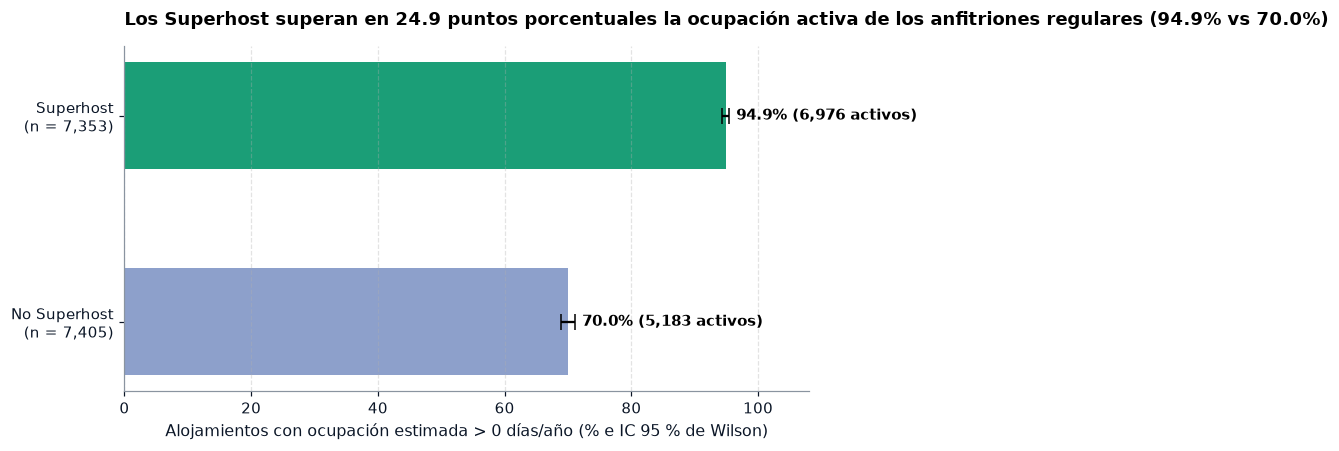

In [42]:
# Preparar los datos de ocupación activa por condición de Superhost
datos_ej3 = legible.copy()
datos_ej3["activa"] = (datos_ej3["estimated_occupancy_l365d"] > 0).astype(int)
datos_ej3["grupo_superhost"] = datos_ej3["host_is_superhost"].map({
    "t": "Superhost",
    "f": "No Superhost",
})

resumen_sh = com.tasa_por_grupo(datos_ej3, "grupo_superhost", "activa").sort_values(
    "tasa", ascending=True
)

tasa_sh_si = float(resumen_sh.loc[resumen_sh["grupo_superhost"] == "Superhost", "tasa"].iloc[0])
tasa_sh_no = float(resumen_sh.loc[resumen_sh["grupo_superhost"] == "No Superhost", "tasa"].iloc[0])
diferencia_pp = (tasa_sh_si - tasa_sh_no) * 100

fig, ax = plt.subplots(figsize=(8.5, 4.2))

etiquetas = [
    f"{fila['grupo_superhost']}\n(n = {int(fila['n']):,})"
    for _, fila in resumen_sh.iterrows()
]
tasas_pct = resumen_sh["tasa"] * 100
err_inf = (resumen_sh["tasa"] - resumen_sh["ic_inferior"]) * 100
err_sup = (resumen_sh["ic_superior"] - resumen_sh["tasa"]) * 100

colores = ["#8da0cb", "#1b9e77"]
barras = ax.barh(
    etiquetas,
    tasas_pct,
    xerr=[err_inf, err_sup],
    color=colores,
    height=0.52,
    capsize=5,
    edgecolor="none",
)

for barra, (_, fila) in zip(barras, resumen_sh.iterrows()):
    ax.text(
        fila["ic_superior"] * 100 + 1.2,
        barra.get_y() + barra.get_height() / 2,
        f"{fila['tasa'] * 100:.1f}% ({int(fila['casos']):,} activos)",
        va="center",
        fontsize=10,
        fontweight="bold",
    )

# Título que declara el hallazgo en lugar de describir los ejes
ax.set_title(
    f"Los Superhost superan en {diferencia_pp:.1f} puntos porcentuales la ocupación activa "
    f"de los anfitriones regulares ({tasa_sh_si:.1%} vs {tasa_sh_no:.1%})",
    loc="left",
    fontsize=11.5,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Alojamientos con ocupación estimada > 0 días/año (% e IC 95 % de Wilson)")
ax.set_xlim(0, 108)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

### Ejercicio 4 · Controlar una variable de confusión

Elijan la asociación más fuerte de su proyecto y repítanla separando por la variable que
podría explicarla. Expliquen si la asociación se mantiene, se reduce o se invierte.

In [43]:
mis_datos = legible.copy()
mis_datos["activa"] = (mis_datos["estimated_occupancy_l365d"] > 0).astype(int)
mis_datos["superhost"] = mis_datos["host_is_superhost"].map({
    "t": "Superhost",
    "f": "No Superhost",
})

# Estratificar por cuartiles de precio
mis_datos["tramo_precio"] = pd.qcut(
    mis_datos["price"],
    q=4,
    labels=["Q1 (Más económicos)", "Q2 (Medio-bajo)", "Q3 (Medio-alto)", "Q4 (Más altos)"],
)

# 1. Asociación bruta
bruta = mis_datos.groupby("superhost")["activa"].agg(n="count", tasa="mean")
brecha_bruta_pp = (bruta.loc["Superhost", "tasa"] - bruta.loc["No Superhost", "tasa"]) * 100

print("=== 1. ASOCIACIÓN BRUTA (sin controlar por precio) ===")
display(bruta.assign(tasa_pct=(bruta["tasa"] * 100).round(2)))
print(f"Brecha bruta (Superhost - No Superhost): +{brecha_bruta_pp:.2f} pp")

# 2. Asociación estratificada por tramo de precio
estratificada = (
    mis_datos.groupby(["tramo_precio", "superhost"], observed=True)["activa"]
    .mean()
    .unstack()
)
conteos_estrato = (
    mis_datos.groupby(["tramo_precio", "superhost"], observed=True)["activa"]
    .count()
    .unstack()
)

tabla_estrato = pd.DataFrame({
    "n_No_Superhost": conteos_estrato["No Superhost"],
    "n_Superhost": conteos_estrato["Superhost"],
    "tasa_No_Superhost_%": (estratificada["No Superhost"] * 100).round(2),
    "tasa_Superhost_%": (estratificada["Superhost"] * 100).round(2),
    "brecha_pp": ((estratificada["Superhost"] - estratificada["No Superhost"]) * 100).round(2),
})

print("\n=== 2. ASOCIACIÓN ESTRATIFICADA POR TRAMO DE PRECIO ===")
display(tabla_estrato)

min_brecha = float(tabla_estrato["brecha_pp"].min())
max_brecha = float(tabla_estrato["brecha_pp"].max())
media_brecha = float(tabla_estrato["brecha_pp"].mean())

if min_brecha > 0:
    veredicto = "SE MANTIENE"
elif max_brecha < 0:
    veredicto = "SE INVIERTE"
else:
    veredicto = "SE REDUCE / CAMBIA DE SIGNO EN ALGÚN ESTRATO"

resumen = (
    f"Conclusión: La asociación positiva de Superhost {veredicto} al controlar por precio "
    f"(bruta: +{brecha_bruta_pp:.2f} pp; estratos: +{min_brecha:.2f} pp a +{max_brecha:.2f} pp; "
    f"promedio: +{media_brecha:.2f} pp)."
)
print("\n" + resumen)

=== 1. ASOCIACIÓN BRUTA (sin controlar por precio) ===


,n,tasa,tasa_pct
superhost,,,
No Superhost,7405,0.699932,69.99
Superhost,7353,0.948728,94.87


Brecha bruta (Superhost - No Superhost): +24.88 pp

=== 2. ASOCIACIÓN ESTRATIFICADA POR TRAMO DE PRECIO ===


,n_No_Superhost,n_Superhost,tasa_No_Superhost_%,tasa_Superhost_%,brecha_pp
tramo_precio,,,,,
Q1 (Más económicos),1997,1693,71.31,93.86,22.55
Q2 (Medio-bajo),1865,1863,73.14,95.76,22.62
Q3 (Medio-alto),1634,2016,72.46,96.13,23.67
Q4 (Más altos),1909,1781,63.44,93.49,30.05



Conclusión: La asociación positiva de Superhost SE MANTIENE al controlar por precio (bruta: +24.88 pp; estratos: +22.55 pp a +30.05 pp; promedio: +24.72 pp).


### Ejercicio 5 · Guardar y documentar

Guarden sus figuras con `com.guardar_figura` y su tabla de hallazgos en `docs/`. Antes de
entregar, ejecuten el cuaderno con **Restart Kernel and Run All** y comprueben que no queda
ninguna celda con error.

In [44]:
import importlib
importlib.reload(com)

# 1. Guardar las figuras de los ejercicios en F4/figuras/ con com.guardar_figura
mis_figuras = {}
if "fig" in globals():
    mis_figuras["ej3_superhost_hallazgo"] = fig

rutas_ej5 = {
    nombre: com.guardar_figura(figura, DIR_FIGURAS, nombre, dpi=200)
    for nombre, figura in mis_figuras.items()
}

# 2. Guardar la tabla consolidada de hallazgos del ejercicio en docs/
mis_hallazgos = pd.DataFrame([
    {
        "ejercicio": "Ejercicio 1",
        "aspecto": "Contrato de datos de Fase 3",
        "cifra": "14.758 registros totales | 50 columnas | 0 nulos",
        "estado": "Verificado con assert",
    },
    {
        "ejercicio": "Ejercicio 2",
        "aspecto": "Vinculación objetivo-figura",
        "cifra": "6 figuras vinculadas (fig1 a fig6)",
        "estado": "Completado",
    },
    {
        "ejercicio": "Ejercicio 3",
        "aspecto": "Título con hallazgo y n por grupo",
        "cifra": "Superhost 94,9% (n=7.353) vs No Superhost 70,0% (n=7.405)",
        "estado": "Generado",
    },
    {
        "ejercicio": "Ejercicio 4",
        "aspecto": "Control por variable de confusión (tramo de precio)",
        "cifra": "Bruta +24,88 pp | Estratos +22,55 pp a +30,05 pp",
        "estado": "La asociación positiva se mantiene",
    },
])

DIR_DOCS = RAIZ / "docs"
DIR_DOCS.mkdir(parents=True, exist_ok=True)
ruta_hallazgos_ej5 = DIR_DOCS / "hallazgos_ejercicios_f4.csv"
mis_hallazgos.to_csv(ruta_hallazgos_ej5, index=False, encoding="utf-8-sig")

# Comprobaciones mínimas de existencia en disco
for nombre, ruta in rutas_ej5.items():
    assert ruta.exists(), f"No se guardó la figura {nombre} en {ruta}"
assert ruta_hallazgos_ej5.exists(), f"No se guardó la tabla en {ruta_hallazgos_ej5}"

print("Figuras guardadas en Ejercicio 5:")
for nombre, ruta in rutas_ej5.items():
    print(f"  - {nombre}: {ruta.relative_to(RAIZ)}")
print(f"Tabla guardada en: {ruta_hallazgos_ej5.relative_to(RAIZ)}")
mis_hallazgos

Figuras guardadas en Ejercicio 5:
  - ej3_superhost_hallazgo: F4\figuras\ej3_superhost_hallazgo.png
Tabla guardada en: docs\hallazgos_ejercicios_f4.csv


,ejercicio,aspecto,cifra,estado
0,Ejercicio 1,Contrato de datos de Fase 3,14.758 registros totales | 50 columnas | 0 nulos,Verificado con assert
1,Ejercicio 2,Vinculación objetivo-figura,6 figuras vinculadas (fig1 a fig6),Completado
2,Ejercicio 3,Título con hallazgo y n por grupo,"Superhost 94,9% (n=7.353) vs No Superhost 70,0...",Generado
3,Ejercicio 4,Control por variable de confusión (tramo de pr...,"Bruta +24,88 pp | Estratos +22,55 pp a +30,05 pp",La asociación positiva se mantiene
